# Stance Detection on Hindi and Bengali Climate Comments: A Reproducible Study
**CSET346, Milestone 2.** Claim: *"Climate change and global warming is a serious concern."* Labels: Favour / Against / None.

No labelled Hindi/Bengali climate stance corpus was released to us, so this notebook builds one and then asks research questions about it.

| RQ | Question | Experiment |
|---|---|---|
| RQ1 | Does machine translated English stance data transfer to real Hindi/Bengali comments? | Train on translated TweetEval, test on real team labelled comments (gold) |
| RQ2 | Does target aware input (claim + comment) help? | Pair vs comment only |
| RQ3 | Does stance framed as NLI help? | mDeBERTa XNLI: zero shot and fine tuned |
| RQ4 | Do translation quality filtering, romanisation augmentation and cleaning help? | Ablations |
| RQ5 | Does an ensemble help, and is the gain significant? | Soft vote, paired bootstrap |
| RQ6 | How robust are models to romanisation, spelling noise, code mixing and social media noise? | Perturbed test sets |

**Protocol.** Training data is translated TweetEval *train* only. Model selection (best epoch) uses translated TweetEval *validation*. Reported results are on (a) translated TweetEval *test* (in distribution, silver) and (b) **gold**, real comments labelled by the team and never used for training or selection. Gold is the number that matters. Every score has a bootstrap 95% confidence interval, and multi seed runs report mean and standard deviation.

Kaggle: GPU on, Internet on. Set `FAST = False` for the final run.

In [1]:
!pip -q install emoji sentencepiece indic-transliteration sentence-transformers peft protobuf

In [2]:
import os, re, json, random, unicodedata, zlib, collections, warnings, sys, time
import numpy as np, pandas as pd, torch, emoji
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.pipeline import make_union
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")

# ------------------------- switches -------------------------
FAST          = True    # True: 1 seed, 3 epochs (quick check). False: 3 seeds, 5 epochs (final report)
RUN_ABLATIONS = True
RUN_LLM       = False   # LoRA fine tune of a small multilingual LLM (slow on a T4)
RUN_GOLD_CV   = False   # few shot: add part of gold to training, 5 fold cross validation
SIM_T         = 0.70    # LaBSE similarity threshold for the translation quality filter
ROMAN_FRAC    = 0.5     # share of training comments that also get a romanised copy
SEEDS  = [42] if FAST else [42, 43, 44]
EPOCHS = 3 if FAST else 5

# ------------------------- data paths -------------------------
GOLD_PATH   = None   # CSV: comment,label,lang   (real comments labelled by the team)
SYNTH_PATH  = None   # CSV: comment,label,lang   (LLM generated, manually checked)
HIDDEN_TEST = None   # CSV: ID,comment           (when the instructor shares it)
YT_API_KEY  = None   # optional, for collecting real comments with the official YouTube Data API

CLAIM  = "Climate change and global warming is a serious concern."
LABELS = ["Favour", "Against", "None"]; L2I = {l: i for i, l in enumerate(LABELS)}
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./out"
os.makedirs(f"{OUT}/probs", exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() else "cpu"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)
print("device:", DEV, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu130


## 1. Data construction
### 1.1 Silver data: TweetEval `stance_climate` (official splits kept), translated to Hindi and Bengali

In [3]:
from datasets import load_dataset
try:    ds = load_dataset("cardiffnlp/tweet_eval", "stance_climate")
except Exception: ds = load_dataset("tweet_eval", "stance_climate")

TW_MAP = {0: "None", 1: "Against", 2: "Favour"}
def clean_en(t):
    t = re.sub(r"@\w+|#SemST|https?://\S+", "", t).replace("#", "")
    return re.sub(r"\s+", " ", t).strip()

en = pd.concat([ds[s].to_pandas().assign(split=s) for s in ds.keys()], ignore_index=True)
en["uid"] = np.arange(len(en)); en["label"] = en["label"].map(TW_MAP); en["en"] = en["text"].apply(clean_en)
print(en.groupby("split")["label"].value_counts().unstack())

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

stance_climate/train-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B / 28.1kB            

stance_climate/train-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

stance_climate/test-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 14.9kB            

stance_climate/test-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

stance_climate/validation-00000-of-00001(…): reconstructing file:   0%|          |  0.00B / 5.47kB            

stance_climate/validation-00000-of-00001(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/355 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/169 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/40 [00:00<?, ? examples/s]

label       Against  Favour  None
split                            
test             11     123    35
train            13     191   151
validation        2      21    17


In [4]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup
NLLB = "facebook/nllb-200-distilled-600M"   # CC-BY-NC 4.0, cite Costa-jussa et al. 2022

def translate(texts, tgt, bs=32):
    tk = AutoTokenizer.from_pretrained(NLLB, src_lang="eng_Latn")
    m = AutoModelForSeq2SeqLM.from_pretrained(NLLB, torch_dtype=torch.float16 if DEV == "cuda" else torch.float32).to(DEV).eval()
    out = []
    for i in range(0, len(texts), bs):
        b = tk(texts[i:i+bs], return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEV)
        with torch.no_grad():
            g = m.generate(**b, forced_bos_token_id=tk.convert_tokens_to_ids(tgt), max_new_tokens=128, num_beams=4)
        out += tk.batch_decode(g, skip_special_tokens=True)
    del m; torch.cuda.empty_cache(); return out

cache = f"{OUT}/silver_v2.csv"
if os.path.exists(cache): silver = pd.read_csv(cache, keep_default_na=False)
else:
    parts = []
    for lang, c in [("Hindi", "hin_Deva"), ("Bengali", "ben_Beng")]:
        parts.append(en[["uid", "split", "label", "en"]].assign(lang=lang, comment=translate(en["en"].tolist(), c)))
    silver = pd.concat(parts, ignore_index=True); silver.to_csv(cache, index=False)
print(silver.shape)

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (8 outputs left out)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

(1128, 6)


### 1.2 Translation quality filter (novel preprocessing step)
Machine translation introduces noise. We embed each English source and its translation with LaBSE and drop *training* pairs whose cosine similarity is below `SIM_T`. Validation and test are never filtered, so the benchmark stays comparable. RQ4 ablates this.

modules.json:   0%|          | 0.00/461 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.02k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.88GB            

... (7 outputs left out)

config.json:   0%|          | 0.00/114 [00:00<?, ?B/s]

2_Dense/model.safetensors: reconstructing file:   0%|          |  0.00B / 2.36MB            

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

         count   mean    std    min    25%    50%    75%    max
lang                                                           
Bengali  564.0  0.804  0.102  0.159  0.754  0.827  0.878  0.965
Hindi    564.0  0.823  0.084  0.416  0.780  0.844  0.879  0.965
training pairs dropped: 0.117


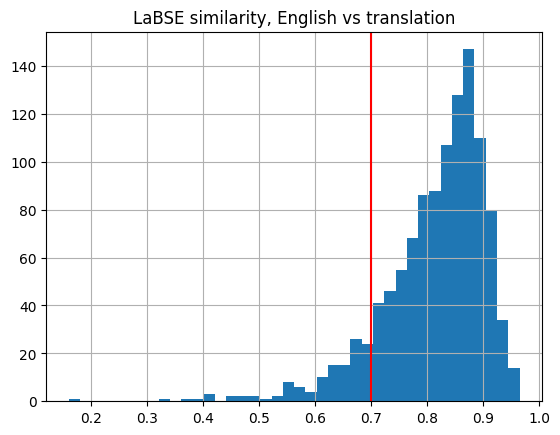

                                                                                                                          en                                                                                                                                                                                                                                                                                                  comment       sim
597                           srsly weirds me out i have to wear sunscreen for the morning dogwalk getting a tan at 9am? wtf  স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স্যার, স  0.159406
995  We blame cities for the majority of CO2 emissions without acknowledging their vulnerability to CFCC15 journey2015 S2228            

In [5]:
from sentence_transformers import SentenceTransformer
labse = SentenceTransformer("sentence-transformers/LaBSE", device=DEV)
a = labse.encode(silver["en"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
b = labse.encode(silver["comment"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
silver["sim"] = (a * b).sum(1); silver["keep"] = silver["sim"] >= SIM_T
del labse; torch.cuda.empty_cache()

print(silver.groupby("lang")["sim"].describe().round(3))
print("training pairs dropped:", (~silver[silver.split == "train"]["keep"]).mean().round(3))
silver["sim"].hist(bins=40); plt.title("LaBSE similarity, English vs translation"); plt.axvline(SIM_T, c="r")
plt.savefig(f"{OUT}/fig_translation_similarity.png", dpi=200); plt.show()
print(silver.sort_values("sim").head(4)[["en", "comment", "sim"]].to_string())

### 1.3 Gold data (real comments), synthetic data, and the helpers to collect them
Gold must be **real YouTube comments in Hindi, Bengali and romanised forms, labelled by the team**. Aim for 300+ (about 100 per class is the minimum for stable class scores). The starter rows below are placeholders so the notebook runs; they are **not** a valid evaluation set.

In [6]:
STARTER = [
 ("जलवायु परिवर्तन सच में बहुत गंभीर समस्या है, पेड़ काटना बंद करो वरना हमारे बच्चे भुगतेंगे", "Favour", "Hindi"),
 ("दिल्ली का प्रदूषण देखकर समझ आता है कि ग्लोबल वार्मिंग कितना खतरनाक है", "Favour", "Hindi"),
 ("global warming bahut serious issue hai, sarkar ko abhi action lena chahiye", "Favour", "Hindi"),
 ("ये सब पश्चिमी देशों का प्रोपेगैंडा है, जलवायु हमेशा से बदलती रही है", "Against", "Hindi"),
 ("ग्लोबल वार्मिंग एक झूठ है, ये बस पैसा कमाने का तरीका है", "Against", "Hindi"),
 ("climate change sirf ek scam hai, pehle bhi garmi sardi hoti thi", "Against", "Hindi"),
 ("वीडियो अच्छा था, चैनल को सब्सक्राइब करो", "None", "Hindi"),
 ("इस वीडियो में कौन सा म्यूजिक है भाई?", "None", "Hindi"),
 ("first comment", "None", "Hindi"),
 ("জলবায়ু পরিবর্তন সত্যিই একটা গুরুতর সমস্যা, এখনই ব্যবস্থা না নিলে বাংলাদেশ তলিয়ে যাবে", "Favour", "Bengali"),
 ("গাছ কাটা বন্ধ করো, নইলে আমাদের ভবিষ্যৎ প্রজন্ম কষ্ট পাবে", "Favour", "Bengali"),
 ("global warming niye ekhon na bhable onek deri hoye jabe", "Favour", "Bengali"),
 ("এসব পশ্চিমা দেশের ষড়যন্ত্র, জলবায়ু আগেও বদলেছে", "Against", "Bengali"),
 ("বিশ্ব উষ্ণায়ন একটা ভাঁওতাবাজি", "Against", "Bengali"),
 ("global warming sob mithya, ager moto i to garom thakto", "Against", "Bengali"),
 ("ভিডিওটা ভালো লেগেছে, চ্যানেলটা সাবস্ক্রাইব করুন", "None", "Bengali"),
 ("এই গানটা কার?", "None", "Bengali"),
 ("প্রথম কমেন্ট", "None", "Bengali"),
]
GOLD_IS_PLACEHOLDER = GOLD_PATH is None
gold = pd.read_csv(GOLD_PATH) if GOLD_PATH else pd.DataFrame(STARTER, columns=["comment", "label", "lang"])
gold = gold.dropna(subset=["comment", "label"]).drop_duplicates("comment").reset_index(drop=True)
assert set(gold["label"]) <= set(LABELS), "labels must be Favour / Against / None"
synth = pd.read_csv(SYNTH_PATH) if SYNTH_PATH else pd.DataFrame(columns=["comment", "label", "lang"])
print("GOLD:", len(gold), "| placeholder:", GOLD_IS_PLACEHOLDER); print(gold.groupby(["lang", "label"]).size().unstack(fill_value=0))
if GOLD_IS_PLACEHOLDER or len(gold) < 150:
    print("\n*** WARNING: gold set is too small for conclusions. Gold numbers below are PRELIMINARY. ***")

GOLD: 18 | placeholder: True
label    Against  Favour  None
lang                          
Bengali        3       3     3
Hindi          3       3     3

*** WARNING: gold set is too small for conclusions. Gold numbers below are PRELIMINARY. ***


In [7]:
# OPTIONAL: collect real comments with the official YouTube Data API (v3), then label them in a sheet.
import requests
def fetch_comments(video_id, api_key, max_n=500):
    rows, tok = [], None
    while len(rows) < max_n:
        r = requests.get("https://www.googleapis.com/youtube/v3/commentThreads",
            params=dict(part="snippet", videoId=video_id, maxResults=100, order="relevance", textFormat="plainText", key=api_key, pageToken=tok)).json()
        for it in r.get("items", []):
            s = it["snippet"]["topLevelComment"]["snippet"]
            rows.append(dict(video=video_id, comment=s["textDisplay"], likes=s["likeCount"]))   # no usernames stored
        tok = r.get("nextPageToken")
        if not tok: break
    return pd.DataFrame(rows)

# Example (set YT_API_KEY first). Then open the CSV in Google Sheets, fill label (Favour/Against/None) and lang (Hindi/Bengali).
# Two annotators per comment: report Cohen's kappa (sklearn.metrics.cohen_kappa_score).
# df = pd.concat([fetch_comments(v, YT_API_KEY) for v in ["VIDEO_ID_1", "VIDEO_ID_2"]]); df["label"] = ""; df["lang"] = ""
# df.to_csv(f"{OUT}/to_label.csv", index=False)

## 2. Preprocessing, augmentation and perturbations
`clean` is the main preprocessing. `to_roman` transliterates native script to Latin to imitate romanised Hinglish/Banglish (approximate: no schwa deletion, so it will not match natural spelling exactly). The same functions create the **robustness test sets** in section 6.

In [8]:
from indic_transliteration import sanscript
SCRIPT_OF = {"Hindi": sanscript.DEVANAGARI, "Bengali": sanscript.BENGALI}

def clean(text):
    t = unicodedata.normalize("NFC", str(text))
    t = re.sub(r"https?://\S+|www\.\S+", " <URL> ", t)
    t = re.sub(r"@\w+", " <USER> ", t)
    t = emoji.demojize(t, delimiters=(" ", " "))
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)
    return re.sub(r"\s+", " ", t).strip()

def to_roman(text, lang):
    t = sanscript.transliterate(str(text), SCRIPT_OF[lang], sanscript.ITRANS)
    t = unicodedata.normalize("NFKD", t)
    t = "".join(c for c in t if not unicodedata.combining(c)).lower()
    t = re.sub(r"[~^]", "", t)
    for a, b in [("aa", "a"), ("ii", "i"), ("uu", "u")]: t = t.replace(a, b)
    return t

def _rng(text, seed): return random.Random(zlib.crc32(str(text).encode()) + seed)

def add_noise(text, lang=None, p=0.07, seed=0):
    r, out, chars = _rng(text, seed), [], list(str(text))
    i = 0
    while i < len(chars):
        c = chars[i]
        if c.isalpha() and r.random() < p:
            op = r.choice(["drop", "dup", "swap"])
            if op == "dup": out += [c, c]
            elif op == "swap" and i + 1 < len(chars): out += [chars[i + 1], c]; i += 1
            elif op == "drop": pass
            else: out.append(c)
        else: out.append(c)
        i += 1
    return "".join(out)

SUBS = {"जलवायु परिवर्तन": "climate change", "प्रदूषण": "pollution", "पर्यावरण": "environment", "सरकार": "government",
        "বিশ্ব উষ্ণায়ন": "global warming", "জলবায়ু পরিবর্তন": "climate change", "দূষণ": "pollution", "পরিবেশ": "environment", "সরকার": "government"}
def code_mix(text, lang=None, seed=0):
    t = str(text)
    for k, v in SUBS.items(): t = t.replace(k, v)
    return t

def social(text, lang=None, seed=0):
    r = _rng(text, seed); t = str(text).rstrip()
    t += " " + r.choice(["😡😡", "🔥", "🌍", "😭😭", "👏👏", "🤣"])
    if r.random() < 0.5: t += r.choice([" http://youtu.be/xyz", " @user"])
    if t and r.random() < 0.5 and t[0].isalpha(): t = t[0] * 3 + t[1:]
    return t

PERTS = {"roman": to_roman, "noise": add_noise, "mix": code_mix, "social": social}

def prep(texts, cfg):
    return [clean(t) if cfg.get("clean", True) else str(t).strip() for t in texts]

# quick self test
for lg, s in [("Hindi", "जलवायु परिवर्तन बहुत गंभीर है"), ("Bengali", "জলবায়ু পরিবর্তন গুরুতর সমস্যা")]:
    print(lg, "|", to_roman(s, lg), "|", code_mix(s), "|", add_noise(s), "|", social(s))

Hindi | jalavayu parivartana bahuta gambhira hai | climate change बहुत गंभीर है | जलवायु परिवर्तन बहुत गंभीर है | जलवायु परिवर्तन बहुत गंभीर है 🔥 http://youtu.be/xyz
Bengali | jalavayau parivartana gurutara samasya | climate change গুরুতর সমস্যা | জলবায়ু পরিবর্তন গুরুতর সমস্যা | জলবায়ু পরিবর্তন গুরুতর সমস্যা 🤣 http://youtu.be/xyz


In [9]:
# Training pool (always from the official TweetEval TRAIN split) and evaluation sets
s_train = silver[silver.split == "train"].copy()
roman_pool = s_train.sample(frac=ROMAN_FRAC, random_state=0).copy()
roman_pool["comment"] = [to_roman(t, l) for t, l in zip(roman_pool["comment"], roman_pool["lang"])]

def make_train(cfg):
    d = s_train[s_train.keep] if cfg.get("filter", True) else s_train
    parts = [d[["comment", "label", "lang"]]]
    if cfg.get("roman_aug", True):
        r = roman_pool[roman_pool.keep] if cfg.get("filter", True) else roman_pool
        parts.append(r[["comment", "label", "lang"]])
    if len(synth): parts.append(synth[["comment", "label", "lang"]])
    return pd.concat(parts, ignore_index=True)

EVAL_RAW = {"val": silver[silver.split == "validation"][["comment", "label", "lang"]].reset_index(drop=True),
            "silver_test": silver[silver.split == "test"][["comment", "label", "lang"]].reset_index(drop=True),
            "gold": gold[["comment", "label", "lang"]].reset_index(drop=True)}
for base in ["silver_test", "gold"]:
    for pn, fn in PERTS.items():
        d = EVAL_RAW[base].copy(); d["comment"] = [fn(t, l) for t, l in zip(d["comment"], d["lang"])]
        EVAL_RAW[f"{base}|{pn}"] = d
HIDDEN = None
if HIDDEN_TEST:
    HIDDEN = pd.read_csv(HIDDEN_TEST); EVAL_RAW["hidden"] = HIDDEN.assign(label="None", lang="Hindi")[["comment", "label", "lang"]]
Y = {k: v["label"].map(L2I).values for k, v in EVAL_RAW.items() if k != "hidden"}
print({k: len(v) for k, v in EVAL_RAW.items()}); print("train rows (default cfg):", len(make_train({})))

{'val': 80, 'silver_test': 338, 'gold': 18, 'silver_test|roman': 338, 'silver_test|noise': 338, 'silver_test|mix': 338, 'silver_test|social': 338, 'gold|roman': 18, 'gold|noise': 18, 'gold|mix': 18, 'gold|social': 18}
train rows (default cfg): 940


## 3. Dataset statistics (for the report)


=== val: n=80 ===
{'Favour': 52.5, 'None': 42.5, 'Against': 5.0} | duplicates: 0
tokens mean/median: 15.4 15.0 | romanised: 0.0 | code mixed: 0.162
label    Against  Favour  None
lang                          
Bengali        2      21    17
Hindi          2      21    17

=== silver_test: n=338 ===
{'Favour': 72.8, 'None': 20.7, 'Against': 6.5} | duplicates: 0
tokens mean/median: 15.6 15.0 | romanised: 0.0 | code mixed: 0.18
label    Against  Favour  None
lang                          
Bengali       11     123    35
Hindi         11     123    35

=== gold: n=18 ===
{'Favour': 33.3, 'Against': 33.3, 'None': 33.3} | duplicates: 0
tokens mean/median: 8.9 10.0 | romanised: 0.278 | code mixed: 0.0
label    Against  Favour  None
lang                          
Bengali        3       3     3
Hindi          3       3     3

=== TRAIN (default config): n=940 ===
{'Favour': 54.8, 'None': 41.6, 'Against': 3.6} | duplicates: 2
tokens mean/median: 15.5 15.0 | romanised: 0.333 | code mixed: 0.116
l

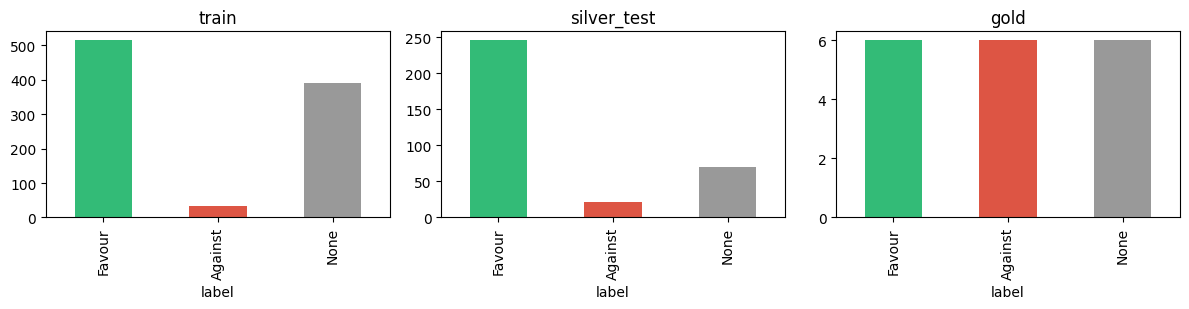

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

google/muril-base-cased subwords per word: 1.51


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

xlm-roberta-base subwords per word: 2.06
Favour ['আমি', 'मैं', 'जलवायु', 'জলবায়ু', 'আমার', 'co', 'हूँ', 'इस', 'था', 'আমরা', 'हो', 'कम']
Against ['হারাতে', 'साल', 'বছরের', 'কোন', 'পারে', 'পরিবর্তন', 'समुद्र', 'ওয়ার্মিং', 'परिवर्तन', 'জলবায়ু', 'जलवायु', 'था']
None ['जलवायु', 'জলবায়ু', 'मैं', 'আমি', 'আমার', 'परिवर्तन', 'हूँ', 'পরিবর্তন', 'इस', 'co', 'प्यार', 'कम']


In [10]:
def script_counts(t):
    return (len(re.findall(r"[\u0900-\u097F]", t)), len(re.findall(r"[\u0980-\u09FF]", t)), len(re.findall(r"[A-Za-z]", t)))
def describe(df, name):
    d = df.copy(); sc = d["comment"].astype(str).apply(script_counts); d["dev"], d["ben"], d["lat"] = zip(*sc)
    tot = (d.dev + d.ben + d.lat).clip(lower=1)
    d["romanised"] = d.lat / tot > 0.8; d["mixed"] = (np.minimum(d.lat, d.dev + d.ben) / tot) > 0.1
    d["tokens"] = d["comment"].astype(str).str.split().str.len()
    print(f"\n=== {name}: n={len(d)} ===")
    print((d["label"].value_counts(normalize=True) * 100).round(1).to_dict(), "| duplicates:", d["comment"].duplicated().sum())
    print("tokens mean/median:", round(d.tokens.mean(), 1), d.tokens.median(), "| romanised:", round(d.romanised.mean(), 3), "| code mixed:", round(d.mixed.mean(), 3))
    print(d.groupby(["lang", "label"]).size().unstack(fill_value=0).to_string())
for n in ["val", "silver_test", "gold"]: describe(EVAL_RAW[n], n)
describe(make_train({}), "TRAIN (default config)")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a_, (n, d) in zip(ax, [("train", make_train({})), ("silver_test", EVAL_RAW["silver_test"]), ("gold", EVAL_RAW["gold"])]):
    d["label"].value_counts().reindex(LABELS).fillna(0).plot.bar(ax=a_, title=n, color=["#3b7", "#d54", "#999"])
plt.tight_layout(); plt.savefig(f"{OUT}/fig_class_distribution.png", dpi=200); plt.show()

# tokenizer fertility
smp = EVAL_RAW["silver_test"]["comment"].sample(300, random_state=0).tolist()
for m in ["google/muril-base-cased", "xlm-roberta-base"]:
    tk = AutoTokenizer.from_pretrained(m); print(m, "subwords per word:", round(np.mean([len(tk.tokenize(t)) / max(1, len(t.split())) for t in smp]), 2))

# class discriminative words (chi2) on the training pool
d = make_train({"roman_aug": False}); cv = CountVectorizer(token_pattern=r"[\u0900-\u097F\u0980-\u09FFA-Za-z]+", min_df=3)
X = cv.fit_transform(d["comment"]); names = cv.get_feature_names_out()
for lab in LABELS:
    sc, _ = chi2(X, (d["label"] == lab).astype(int)); print(lab, list(names[np.argsort(-np.nan_to_num(sc))[:12]]))

## 4. Metrics: bootstrap confidence intervals, paired significance, calibration

In [11]:
def macro_f1(y, p): return f1_score(y, p, average="macro", labels=[0, 1, 2], zero_division=0)

def boot_ci(y, p, n=1000, seed=0):
    r = np.random.RandomState(seed); idx = r.randint(0, len(y), (n, len(y)))
    s = [macro_f1(y[i], p[i]) for i in idx]; return float(np.percentile(s, 2.5)), float(np.percentile(s, 97.5))

def paired_boot(y, pa, pb, n=2000, seed=0):
    """Return mean F1 difference (a minus b) and one sided p-value for 'a is not better than b'."""
    r = np.random.RandomState(seed); idx = r.randint(0, len(y), (n, len(y)))
    diff = np.array([macro_f1(y[i], pa[i]) - macro_f1(y[i], pb[i]) for i in idx]); return float(diff.mean()), float((diff <= 0).mean())

def ece(probs, y, bins=10):
    conf, pred = probs.max(1), probs.argmax(1); acc = (pred == y).astype(float); e = 0
    for lo in np.linspace(0, 1, bins, endpoint=False):
        m = (conf > lo) & (conf <= lo + 1 / bins)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)

# sanity test of the metric code
_y = np.array([0, 1, 2, 0, 1, 2] * 10); _p = _y.copy(); _p[:6] = (_p[:6] + 1) % 3
print("macro F1", round(macro_f1(_y, _p), 3), "CI", boot_ci(_y, _p), "paired", paired_boot(_y, _y, _p))

macro F1 0.9 CI (0.8125044249964717, 0.9672765627829254) paired (0.10224442632830995, 0.003)


## 5. Experiment engine
One function trains any model under any configuration and saves class probabilities for **every** evaluation set (clean, perturbed, hidden). Results are cached to disk, so a crashed Kaggle session can resume.

In [12]:
NLI_MODEL = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"   # labels: 0 entailment, 1 neutral, 2 contradiction
NLI_PERM = np.array([0, 2, 1])   # our order (Favour, Against, None) <-> NLI order; self inverse
BASE = dict(clean=True, filter=True, roman_aug=True, pair=True, weighted=True, epochs=EPOCHS, lr=2e-5, bs=16)

class DS(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tok, cfg, maxlen=128):
        texts = list(texts)
        if cfg.get("llm"):          enc = tok([f"Claim: {CLAIM}\nComment: {t}\nStance:" for t in texts], truncation=True, max_length=maxlen + 40)
        elif not cfg["pair"]:       enc = tok(texts, truncation=True, max_length=maxlen)
        elif cfg.get("nli"):        enc = tok(texts, [CLAIM] * len(texts), truncation=True, max_length=maxlen)   # premise = comment, hypothesis = claim
        else:                       enc = tok([CLAIM] * len(texts), texts, truncation=True, max_length=maxlen)   # claim [SEP] comment
        self.enc, self.y = enc, labels
    def __len__(self): return len(self.enc["input_ids"])
    def __getitem__(self, i):
        d = {k: v[i] for k, v in self.enc.items()}
        if self.y is not None: d["labels"] = int(self.y[i])
        return d

@torch.no_grad()
def predict(model, tok, texts, cfg, bs=64):
    model.eval(); out = []
    for b in torch.utils.data.DataLoader(DS(texts, None, tok, cfg), batch_size=bs, collate_fn=DataCollatorWithPadding(tok)):
        b = {k: v.to(DEV) for k, v in b.items()}
        with torch.autocast("cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
            lg = model(**b).logits.float()
        out.append(torch.softmax(lg, -1).cpu().numpy())
    p = np.concatenate(out); return p[:, NLI_PERM] if cfg.get("nli") else p

def fit_predict(cfg, seed, tr_df, eval_texts, keep=False):
    set_seed(seed); name = cfg["model"]
    tok = AutoTokenizer.from_pretrained(name, use_fast=not cfg.get("slow_tok", False))
    if cfg.get("llm"):
        from peft import LoraConfig, get_peft_model
        tok.pad_token = tok.pad_token or tok.eos_token; tok.padding_side = "right"
        model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=3, torch_dtype=torch.float16)
        model.config.pad_token_id = tok.pad_token_id
        model = get_peft_model(model, LoraConfig(task_type="SEQ_CLS", r=16, lora_alpha=32, lora_dropout=0.05,
                                                 target_modules=["q_proj", "k_proj", "v_proj", "o_proj"]))
        for p in model.parameters():
            if p.requires_grad:
                p.data = p.data.float()      # trainable LoRA + head weights in fp32
            else:
                p.data = p.data.half()       # frozen base weights stay fp16
    else:
        model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=3, ignore_mismatched_sizes=True)
        model = model.float()   # some checkpoints (mDeBERTa) are stored in fp16; AMP needs fp32 master weights
    model.to(DEV)
    y = tr_df["label"].map(L2I).values; ymap = NLI_PERM if cfg.get("nli") else np.arange(3)
    if cfg["epochs"] > 0:
        ds_ = DS(prep(tr_df["comment"], cfg), ymap[y], tok, cfg)
        dl = torch.utils.data.DataLoader(ds_, batch_size=cfg["bs"], shuffle=True, collate_fn=DataCollatorWithPadding(tok))
        cnt = np.bincount(y, minlength=3); w = len(y) / (3 * np.maximum(cnt, 1)) if cfg["weighted"] else np.ones(3)
        wt = torch.tensor(w[np.argsort(ymap)] if cfg.get("nli") else w, dtype=torch.float, device=DEV)
        lossf = torch.nn.CrossEntropyLoss(weight=wt)
        params = [p for p in model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=0.01)
        sch = get_linear_schedule_with_warmup(opt, int(0.1 * len(dl) * cfg["epochs"]), len(dl) * cfg["epochs"])
        scaler = torch.amp.GradScaler("cuda", enabled=(DEV == "cuda")); best, best_state = -1, None
        for ep in range(cfg["epochs"]):
            model.train(); tot = 0
            for b in dl:
                b = {k: v.to(DEV) for k, v in b.items()}; lab = b.pop("labels")
                with torch.autocast("cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
                    loss = lossf(model(**b).logits.float(), lab)
                opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(params, 1.0); scaler.step(opt); scaler.update(); sch.step(); tot += loss.item()
            vf1 = macro_f1(Y["val"], predict(model, tok, eval_texts["val"], cfg).argmax(1))
            print(f"  [{name.split('/')[-1]} seed {seed}] epoch {ep+1} loss {tot/len(dl):.3f} val macroF1 {vf1:.3f}")
            if vf1 > best: best, best_state = vf1, {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}
        with torch.no_grad():
            for n, p in model.named_parameters():
                if n in best_state: p.copy_(best_state[n].to(p.device))
    res = {k: predict(model, tok, v, cfg) for k, v in eval_texts.items()}
    if keep: return res, model, tok
    del model; torch.cuda.empty_cache(); return res

def run_cfg(name, cfg, seeds=None):
    seeds = seeds or SEEDS
    if cfg["epochs"] == 0: seeds = seeds[:1]   # zero shot needs no training, so one run is enough
    for s in seeds:
        f = f"{OUT}/probs/{name}__{s}.npz"
        if os.path.exists(f) and set(k.replace("~", "|") for k in np.load(f).files) >= set(EVAL_RAW): continue
        t0 = time.time(); texts = {k: prep(v["comment"], cfg) for k, v in EVAL_RAW.items()}
        res = fit_predict(cfg, s, make_train(cfg), texts)
        np.savez_compressed(f, **{k.replace("|", "~"): v for k, v in res.items()}); print(f"{name} seed {s} done in {time.time()-t0:.0f}s")

def load_probs(name):
    out = collections.defaultdict(list)
    for f in sorted(os.listdir(f"{OUT}/probs")):
        if f.startswith(name + "__"):
            z = np.load(f"{OUT}/probs/{f}")
            for k in z.files: out[k.replace("~", "|")].append(z[k])
    return out

### 5.1 Baseline: TF-IDF + Logistic Regression

In [13]:
def run_tfidf(name="tfidf_lr", cfg=BASE):
    tr = make_train(cfg); vec = make_union(TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                                           TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True))
    X = vec.fit_transform(prep(tr["comment"], cfg)); clf = LogisticRegression(max_iter=3000, class_weight="balanced", C=3).fit(X, tr["label"].map(L2I))
    res = {k: clf.predict_proba(vec.transform(prep(v["comment"], cfg))) for k, v in EVAL_RAW.items()}
    np.savez_compressed(f"{OUT}/probs/{name}__0.npz", **{k.replace("|", "~"): v for k, v in res.items()})
run_tfidf()
print("baseline done")

baseline done


### 5.2 Main models and ablations
`mdeberta_nli_zeroshot` uses the NLI model with no stance training (RQ3). `mdeberta_nli_ft` fine tunes it on stance framed as NLI. Ablations all use XLM-R base and change one factor at a time (RQ2, RQ4).

In [14]:
MAIN = {
 "xlmr_pair":   {**BASE, "model": "xlm-roberta-base"},
 "muril_pair":  {**BASE, "model": "google/muril-base-cased"},
 "mdeberta_nli_zeroshot": {**BASE, "model": NLI_MODEL, "nli": True, "slow_tok": True, "epochs": 0},
 "mdeberta_nli_ft":       {**BASE, "model": NLI_MODEL, "nli": True, "slow_tok": True},
}
ABL = {
 "xlmr_single":      {**MAIN["xlmr_pair"], "pair": False},          # RQ2: no claim in the input
 "xlmr_noclean":     {**MAIN["xlmr_pair"], "clean": False},
 "xlmr_nofilter":    {**MAIN["xlmr_pair"], "filter": False},        # RQ4: no LaBSE filter
 "xlmr_noromanaug":  {**MAIN["xlmr_pair"], "roman_aug": False},
 "xlmr_unweighted":  {**MAIN["xlmr_pair"], "weighted": False},
}
if RUN_LLM: MAIN["qwen_lora"] = {**BASE, "model": "Qwen/Qwen2.5-1.5B-Instruct", "llm": True, "bs": 8, "lr": 1e-4}

for n, c in MAIN.items(): run_cfg(n, c)
if RUN_ABLATIONS:
    for n, c in ABL.items(): run_cfg(n, c)
json.dump({"MAIN": MAIN, "ABL": ABL, "seeds": SEEDS, "SIM_T": SIM_T, "ROMAN_FRAC": ROMAN_FRAC, "nllb": NLLB}, open(f"{OUT}/run_config.json", "w"), indent=1)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [xlm-roberta-base seed 42] epoch 1 loss 1.122 val macroF1 0.199
  [xlm-roberta-base seed 42] epoch 2 loss 1.082 val macroF1 0.536
  [xlm-roberta-base seed 42] epoch 3 loss 1.017 val macroF1 0.580
xlmr_pair seed 42 done in 47s


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

... (31 outputs left out)

  [xlm-roberta-base seed 42] epoch 1 loss 1.104 val macroF1 0.230
  [xlm-roberta-base seed 42] epoch 2 loss 1.065 val macroF1 0.521
  [xlm-roberta-base seed 42] epoch 3 loss 0.920 val macroF1 0.562
xlmr_noromanaug seed 42 done in 30s


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [xlm-roberta-base seed 42] epoch 1 loss 0.866 val macroF1 0.504
  [xlm-roberta-base seed 42] epoch 2 loss 0.741 val macroF1 0.528
  [xlm-roberta-base seed 42] epoch 3 loss 0.624 val macroF1 0.568
xlmr_unweighted seed 42 done in 39s


## 6. Results
Primary metric is macro F1 (the course metric). `f1_mean ± f1_std` is over seeds; the confidence interval is a bootstrap over test comments for the seed averaged prediction.

In [15]:
def table(names, ev):
    rows = []
    for n in names:
        P = load_probs(n)
        if ev not in P: continue
        y = Y[ev]; per = [macro_f1(y, p.argmax(1)) for p in P[ev]]; pm = np.mean(P[ev], 0); pr = pm.argmax(1); lo, hi = boot_ci(y, pr)
        rows.append(dict(model=n, f1_mean=round(np.mean(per), 4), f1_std=round(np.std(per), 4), f1_ci=f"[{lo:.3f}, {hi:.3f}]",
                         accuracy=round(accuracy_score(y, pr), 4), ece=round(ece(pm, y), 3)))
    return pd.DataFrame(rows)

ALL = ["tfidf_lr"] + list(MAIN) + (list(ABL) if RUN_ABLATIONS else [])
res_gold = table(ALL, "gold"); res_silver = table(ALL, "silver_test")
print("GOLD (real comments, transfer from translated data)" + ("  *** PRELIMINARY: placeholder/small gold ***" if GOLD_IS_PLACEHOLDER or len(gold) < 150 else ""))
display(res_gold); print("SILVER TEST (translated TweetEval test, in distribution)"); display(res_silver)
res_gold.to_csv(f"{OUT}/results_gold.csv", index=False); res_silver.to_csv(f"{OUT}/results_silver_test.csv", index=False)
print(res_gold.to_latex(index=False))

GOLD (real comments, transfer from translated data)  *** PRELIMINARY: placeholder/small gold ***


,model,f1_mean,f1_std,f1_ci,accuracy,ece
0,tfidf_lr,0.4630,0.0,"[0.307, 0.583]",0.5556,0.162
1,xlmr_pair,0.5430,0.0,"[0.418, 0.622]",0.6667,0.106
2,muril_pair,0.5038,0.0,"[0.374, 0.607]",0.6111,0.259
3,mdeberta_nli_zeroshot,0.6897,0.0,"[0.424, 0.885]",0.7222,0.257
4,mdeberta_nli_ft,0.8222,0.0,"[0.600, 1.000]",0.8333,0.157
5,xlmr_single,0.4940,0.0,"[0.327, 0.593]",0.6111,0.049
6,xlmr_noclean,0.4889,0.0,"[0.333, 0.605]",0.6111,0.133
7,xlmr_nofilter,0.5430,0.0,"[0.418, 0.622]",0.6667,0.131
8,xlmr_noromanaug,0.5430,0.0,"[0.418, 0.622]",0.6667,0.324
9,xlmr_unweighted,0.5556,0.0,"[0.455, 0.625]",0.6667,0.232


SILVER TEST (translated TweetEval test, in distribution)


,model,f1_mean,f1_std,f1_ci,accuracy,ece
0,tfidf_lr,0.4275,0.0,"[0.387, 0.464]",0.6982,0.029
1,xlmr_pair,0.4973,0.0,"[0.459, 0.532]",0.7781,0.075
2,muril_pair,0.4710,0.0,"[0.435, 0.506]",0.7367,0.385
3,mdeberta_nli_zeroshot,0.1800,0.0,"[0.150, 0.209]",0.2751,0.607
4,mdeberta_nli_ft,0.5267,0.0,"[0.475, 0.581]",0.7722,0.172
5,xlmr_single,0.4565,0.0,"[0.418, 0.494]",0.7249,0.217
6,xlmr_noclean,0.4841,0.0,"[0.446, 0.519]",0.7633,0.084
7,xlmr_nofilter,0.4727,0.0,"[0.433, 0.508]",0.7456,0.161
8,xlmr_noromanaug,0.4979,0.0,"[0.457, 0.534]",0.7781,0.126
9,xlmr_unweighted,0.4878,0.0,"[0.448, 0.527]",0.7751,0.107


\begin{tabular}{lrrlrr}
\toprule
model & f1_mean & f1_std & f1_ci & accuracy & ece \\
\midrule
tfidf_lr & 0.463000 & 0.000000 & [0.307, 0.583] & 0.555600 & 0.162000 \\
xlmr_pair & 0.543000 & 0.000000 & [0.418, 0.622] & 0.666700 & 0.106000 \\
muril_pair & 0.503800 & 0.000000 & [0.374, 0.607] & 0.611100 & 0.259000 \\
mdeberta_nli_zeroshot & 0.689700 & 0.000000 & [0.424, 0.885] & 0.722200 & 0.257000 \\
mdeberta_nli_ft & 0.822200 & 0.000000 & [0.600, 1.000] & 0.833300 & 0.157000 \\
xlmr_single & 0.494000 & 0.000000 & [0.327, 0.593] & 0.611100 & 0.049000 \\
xlmr_noclean & 0.488900 & 0.000000 & [0.333, 0.605] & 0.611100 & 0.133000 \\
xlmr_nofilter & 0.543000 & 0.000000 & [0.418, 0.622] & 0.666700 & 0.131000 \\
xlmr_noromanaug & 0.543000 & 0.000000 & [0.418, 0.622] & 0.666700 & 0.324000 \\
xlmr_unweighted & 0.555600 & 0.000000 & [0.455, 0.625] & 0.666700 & 0.232000 \\
\bottomrule
\end{tabular}



### 6.1 Ensemble and significance (RQ5)
Soft vote over the strongest models, plus a variant weighted by validation macro F1. Significance uses a paired bootstrap on the same comments.

In [16]:
members = [m for m in ["xlmr_pair", "muril_pair", "mdeberta_nli_ft", "qwen_lora"] if load_probs(m)]
Pm = {m: {k: np.mean(v, 0) for k, v in load_probs(m).items()} for m in members}
wts = np.array([macro_f1(Y["val"], Pm[m]["val"].argmax(1)) for m in members]); wts = wts / wts.sum()
for nm, w in [("ens_soft", np.ones(len(members)) / len(members)), ("ens_weighted", wts)]:
    res = {k: sum(wi * Pm[m][k] for wi, m in zip(w, members)) for k in EVAL_RAW}
    np.savez_compressed(f"{OUT}/probs/{nm}__0.npz", **{k.replace("|", "~"): v for k, v in res.items()})
print("ensemble members:", members, "weights:", wts.round(3))

ALL2 = ["tfidf_lr"] + members + ["ens_soft", "ens_weighted"]
for ev in ["gold", "silver_test"]:
    print("\n", ev); display(table(ALL2, ev))
    y = Y[ev]; get = lambda n: np.mean(load_probs(n)[ev], 0).argmax(1)
    for a_, b_ in [("ens_weighted", "tfidf_lr"), ("ens_weighted", members[0]), ("mdeberta_nli_ft", "xlmr_pair")]:
        if a_ in ALL2 + members and b_ in ALL2 + members:
            d, p = paired_boot(y, get(a_), get(b_)); print(f"  {a_} minus {b_}: dF1={d:+.3f}  p(not better)={p:.3f}")

ensemble members: ['xlmr_pair', 'muril_pair', 'mdeberta_nli_ft'] weights: [0.331 0.337 0.331]

 gold


,model,f1_mean,f1_std,f1_ci,accuracy,ece
0,tfidf_lr,0.4630,0.0,"[0.307, 0.583]",0.5556,0.162
1,xlmr_pair,0.5430,0.0,"[0.418, 0.622]",0.6667,0.106
2,muril_pair,0.5038,0.0,"[0.374, 0.607]",0.6111,0.259
3,mdeberta_nli_ft,0.8222,0.0,"[0.600, 1.000]",0.8333,0.157
4,ens_soft,0.8222,0.0,"[0.600, 1.000]",0.8333,0.186
5,ens_weighted,0.8222,0.0,"[0.600, 1.000]",0.8333,0.187


  ens_weighted minus tfidf_lr: dF1=+0.353  p(not better)=0.001
  ens_weighted minus xlmr_pair: dF1=+0.272  p(not better)=0.039
  mdeberta_nli_ft minus xlmr_pair: dF1=+0.272  p(not better)=0.039

 silver_test


,model,f1_mean,f1_std,f1_ci,accuracy,ece
0,tfidf_lr,0.4275,0.0,"[0.387, 0.464]",0.6982,0.029
1,xlmr_pair,0.4973,0.0,"[0.459, 0.532]",0.7781,0.075
2,muril_pair,0.4710,0.0,"[0.435, 0.506]",0.7367,0.385
3,mdeberta_nli_ft,0.5267,0.0,"[0.475, 0.581]",0.7722,0.172
4,ens_soft,0.4974,0.0,"[0.461, 0.532]",0.7692,0.142
5,ens_weighted,0.4974,0.0,"[0.461, 0.532]",0.7692,0.143


  ens_weighted minus tfidf_lr: dF1=+0.071  p(not better)=0.001
  ens_weighted minus xlmr_pair: dF1=+0.001  p(not better)=0.478
  mdeberta_nli_ft minus xlmr_pair: dF1=+0.029  p(not better)=0.146


### 6.2 Robustness (RQ6): drop in macro F1 under perturbation
`roman` = native script to Latin, `noise` = character level typos, `mix` = domain words replaced by English, `social` = emoji, URLs, elongation.

perturbation,mix,noise,roman,social
model,,,,
ens_weighted,0.002,0.018,0.098,-0.001
mdeberta_nli_ft,0.000,0.037,0.158,0.027
muril_pair,0.012,0.001,0.034,-0.006
tfidf_lr,0.007,0.005,0.032,0.004
xlmr_pair,0.001,0.049,0.116,0.037


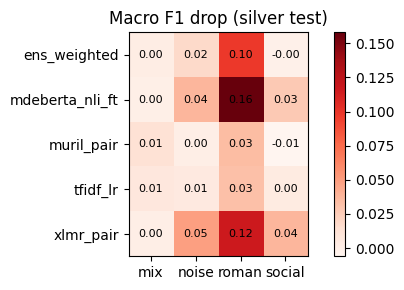

In [17]:
rows = []
for n in ["tfidf_lr", "xlmr_pair", "muril_pair", "mdeberta_nli_ft", "ens_weighted"]:
    P = load_probs(n)
    if not P: continue
    for base in ["silver_test", "gold"]:
        f0 = macro_f1(Y[base], np.mean(P[base], 0).argmax(1))
        for pn in PERTS:
            f1_ = macro_f1(Y[f"{base}|{pn}"], np.mean(P[f"{base}|{pn}"], 0).argmax(1))
            rows.append(dict(model=n, data=base, perturbation=pn, clean_f1=round(f0, 3), perturbed_f1=round(f1_, 3), drop=round(f0 - f1_, 3)))
rob = pd.DataFrame(rows); rob.to_csv(f"{OUT}/results_robustness.csv", index=False)
piv = rob[rob.data == "silver_test"].pivot(index="model", columns="perturbation", values="drop"); display(piv)
plt.figure(figsize=(5.5, 3)); plt.imshow(piv.values, cmap="Reds"); plt.xticks(range(piv.shape[1]), piv.columns); plt.yticks(range(piv.shape[0]), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]): plt.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Macro F1 drop (silver test)"); plt.colorbar(); plt.tight_layout(); plt.savefig(f"{OUT}/fig_robustness.png", dpi=200); plt.show()

## 7. Error analysis and explainability
### 7.1 Slice analysis and automatic error tags

In [18]:
BEST = "ens_weighted"; P = {k: v[0] for k, v in load_probs(BEST).items()}
NEG = r"नहीं|नही|मत\b|\bna\b|nahi|nahin|না\b|নি\b|নেই|\bnei\b|\bnot\b|\bno\b"
def tags(df):
    t = df["comment"].astype(str); sc = t.apply(script_counts); lat = np.array([s[2] for s in sc]); nat = np.array([s[0] + s[1] for s in sc])
    return pd.DataFrame({"question": t.str.contains(r"\?|\u061f"), "short(<=3 tokens)": t.str.split().str.len() <= 3, "negation_cue": t.str.contains(NEG, case=False, regex=True),
                         "romanised": lat / np.maximum(1, lat + nat) > 0.8, "has_emoji": t.apply(lambda x: emoji.emoji_count(x) > 0), "has_url_or_mention": t.str.contains(r"http|@\w+")})
rows, errs = [], []
for ev in ["silver_test", "gold"]:
    d = EVAL_RAW[ev].copy(); d["pred"] = [LABELS[i] for i in P[ev].argmax(1)]; d["wrong"] = d["label"] != d["pred"]; tg = tags(d)
    for lg in d["lang"].unique(): rows.append(dict(data=ev, slice=f"lang={lg}", n=int((d.lang == lg).sum()), macroF1=round(macro_f1(Y[ev][(d.lang == lg).values], P[ev].argmax(1)[(d.lang == lg).values]), 3)))
    for c in tg.columns:
        m = tg[c].values
        if m.sum() > 0: rows.append(dict(data=ev, slice=c, n=int(m.sum()), macroF1=round(macro_f1(Y[ev][m], P[ev].argmax(1)[m]), 3), error_rate=round(d.wrong[m].mean(), 3)))
    errs.append(pd.concat([d[d.wrong], tg[d.wrong.values]], axis=1).assign(set=ev))
sl = pd.DataFrame(rows); display(sl); sl.to_csv(f"{OUT}/results_slices.csv", index=False)
err = pd.concat(errs); err["error_type"] = ""   # fill manually: sarcasm / implicit stance / None-vs-Favour / noisy translation / label noise
err.to_csv(f"{OUT}/errors_to_annotate.csv", index=False); print(len(err), "errors saved. Annotate error_type by hand for the report.")

for ev in ["silver_test", "gold"]:
    cm = confusion_matrix(Y[ev], P[ev].argmax(1), labels=[0, 1, 2]); print(ev, "confusion matrix (rows true, cols pred):", LABELS); print(cm)
    print(classification_report(Y[ev], P[ev].argmax(1), target_names=LABELS, zero_division=0))

,data,slice,n,macroF1,error_rate
0,silver_test,lang=Hindi,169,0.518,NaN
1,silver_test,lang=Bengali,169,0.477,NaN
2,silver_test,question,49,0.484,0.265
3,silver_test,short(<=3 tokens),3,0.333,0.000
4,silver_test,negation_cue,100,0.504,0.230
5,gold,lang=Hindi,9,0.886,NaN
6,gold,lang=Bengali,9,0.750,NaN
7,gold,question,2,0.333,0.000
8,gold,short(<=3 tokens),3,0.333,0.000
9,gold,negation_cue,2,0.333,0.000


81 errors saved. Annotate error_type by hand for the report.
silver_test confusion matrix (rows true, cols pred): ['Favour', 'Against', 'None']
[[210   3  33]
 [ 18   0   4]
 [ 17   3  50]]
              precision    recall  f1-score   support

      Favour       0.86      0.85      0.86       246
     Against       0.00      0.00      0.00        22
        None       0.57      0.71      0.64        70

    accuracy                           0.77       338
   macro avg       0.48      0.52      0.50       338
weighted avg       0.74      0.77      0.75       338

gold confusion matrix (rows true, cols pred): ['Favour', 'Against', 'None']
[[6 0 0]
 [3 3 0]
 [0 0 6]]
              precision    recall  f1-score   support

      Favour       0.67      1.00      0.80         6
     Against       1.00      0.50      0.67         6
        None       1.00      1.00      1.00         6

    accuracy                           0.83        18
   macro avg       0.89      0.83      0.82        18

### 7.2 Explainability: word occlusion attribution
For a comment, remove one word at a time and measure the drop in the predicted class probability. Large drops mark the words the model relies on. This checks for keyword and shortcut reliance.

In [19]:
XAI_CFG = MAIN["xlmr_pair"]
_, xmodel, xtok = fit_predict(XAI_CFG, SEEDS[0], make_train(XAI_CFG), {"val": prep(EVAL_RAW["val"]["comment"], XAI_CFG)}, keep=True)

def occlusion(text, topk=5):
    words = clean(text).split(); base = predict(xmodel, xtok, [" ".join(words)], XAI_CFG)[0]; c = int(base.argmax())
    var = [" ".join(words[:i] + words[i+1:]) for i in range(len(words))]
    drops = base[c] - predict(xmodel, xtok, var, XAI_CFG)[:, c]
    return LABELS[c], float(base[c]), sorted(zip(words, drops.round(3)), key=lambda x: -x[1])[:topk]

demo = EVAL_RAW["gold"].sample(min(8, len(EVAL_RAW["gold"])), random_state=1)
for t, y_ in zip(demo["comment"], demo["label"]):
    lab, pr, top = occlusion(t); print(f"TRUE={y_:8s} PRED={lab:8s} ({pr:.2f}) | {t[:90]}\n    key words: {top}")
del xmodel; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [xlm-roberta-base seed 42] epoch 1 loss 1.122 val macroF1 0.199
  [xlm-roberta-base seed 42] epoch 2 loss 1.082 val macroF1 0.536
  [xlm-roberta-base seed 42] epoch 3 loss 1.017 val macroF1 0.580
TRUE=None     PRED=None     (0.77) | वीडियो अच्छा था, चैनल को सब्सक्राइब करो
    key words: [('अच्छा', np.float32(0.045)), ('था,', np.float32(0.038)), ('करो', np.float32(-0.009)), ('को', np.float32(-0.018)), ('वीडियो', np.float32(-0.021))]
TRUE=Against  PRED=Favour   (0.75) | ये सब पश्चिमी देशों का प्रोपेगैंडा है, जलवायु हमेशा से बदलती रही है
    key words: [('जलवायु', np.float32(0.616)), ('है,', np.float32(0.016)), ('देशों', np.float32(0.008)), ('बदलती', np.float32(0.006)), ('का', np.float32(0.003))]
TRUE=Against  PRED=Favour   (0.73) | বিশ্ব উষ্ণায়ন একটা ভাঁওতাবাজি
    key words: [('উষ্ণায়ন', np.float32(0.535)), ('ভাঁওতাবাজি', np.float32(0.256)), ('বিশ্ব', np.float32(0.061)), ('একটা', np.float32(0.044))]
TRUE=Favour   PRED=Favour   (0.67) | global warming bahut serious issue hai, sarkar 

## 8. Optional: few shot use of gold (cross validation)
Adds part of gold to training and tests on the held out fold. Run only once gold has 150+ rows.

In [20]:
if RUN_GOLD_CV:
    from sklearn.model_selection import StratifiedKFold
    cfg = MAIN["xlmr_pair"]; oof = np.zeros((len(gold), 3)); g = EVAL_RAW["gold"]
    for k, (tr_i, te_i) in enumerate(StratifiedKFold(5, shuffle=True, random_state=0).split(g, g["label"])):
        extra = pd.concat([g.iloc[tr_i]] * 5, ignore_index=True)      # upweight real data x5
        res = fit_predict(cfg, SEEDS[0], pd.concat([make_train(cfg), extra], ignore_index=True),
                          {"val": prep(EVAL_RAW["val"]["comment"], cfg), "fold": prep(g.iloc[te_i]["comment"], cfg)})
        oof[te_i] = res["fold"]
    zero = np.mean(load_probs("xlmr_pair")["gold"], 0)
    print("gold macro F1  zero gold:", round(macro_f1(Y["gold"], zero.argmax(1)), 3), "| + gold CV:", round(macro_f1(Y["gold"], oof.argmax(1)), 3))
else: print("RUN_GOLD_CV is False")

RUN_GOLD_CV is False


## 9. Prediction file and reproducibility record

In [21]:
if HIDDEN is not None:
    ph = {k: v[0] for k, v in load_probs("ens_weighted").items()}["hidden"]
    pd.DataFrame({"ID": HIDDEN["ID"], "Predicted Label": [LABELS[i] for i in ph.argmax(1)]}).to_csv(f"{OUT}/predictions.csv", index=False)
    print("predictions.csv written")
else: print("No hidden test set yet. Set HIDDEN_TEST and re-run sections 1.3 to 6 (cached models are re-used where possible).")
import transformers, sklearn
json.dump({"torch": torch.__version__, "transformers": transformers.__version__, "sklearn": sklearn.__version__, "seeds": SEEDS, "epochs": EPOCHS,
           "gold_rows": len(gold), "gold_placeholder": GOLD_IS_PLACEHOLDER}, open(f"{OUT}/environment.json", "w"), indent=1)
print(sorted(os.listdir(OUT)))

No hidden test set yet. Set HIDDEN_TEST and re-run sections 1.3 to 6 (cached models are re-used where possible).
['.virtual_documents', 'environment.json', 'errors_to_annotate.csv', 'fig_class_distribution.png', 'fig_robustness.png', 'fig_translation_similarity.png', 'probs', 'results_gold.csv', 'results_robustness.csv', 'results_silver_test.csv', 'results_slices.csv', 'run_config.json', 'silver_v2.csv']
